In [7]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import math
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
from utils import load_checkpoint, train_func_classification


d:\anaconda3\envs\CS2109S\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from torch_influence.base import BaseObjective
from torch_influence.modules import CGInfluenceModule, LiSSAInfluenceModule, AutogradInfluenceModule
from utils import train_func_classification


In [9]:
class SinDataset(Dataset):
    def __init__(self, n_samples=2000, x_min=-2 * math.pi, x_max=2 * math.pi):
        self.n_samples = n_samples
        self.x_vals = torch.linspace(x_min, x_max, n_samples).unsqueeze(-1).float()
        self.y_vals = torch.sin(self.x_vals).float()
    
    def __len__(self):
        return self.n_samples
    
    def __getitem__(self, idx):
        return self.x_vals[idx], self.y_vals[idx]
    
class ValidationSinDataset(Dataset):
    def __init__(self, n_samples=200, x_min=-2 * math.pi, x_max=2 * math.pi):
        self.n_samples = n_samples
        x_vals = (x_max - x_min) * torch.rand(n_samples) + x_min
        self.x_vals = x_vals.unsqueeze(-1).float()
        self.y_vals = torch.sin(self.x_vals).float()
    
    def __len__(self):
        return self.n_samples
    
    def __getitem__(self, idx):
        return self.x_vals[idx], self.y_vals[idx]

train_dataset = SinDataset()
# train_dataset.x_vals = train_dataset.x_vals.view(-1, 1)
validation_dataset = ValidationSinDataset()

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=8, shuffle=False)

In [10]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
    
mnist_train = datasets.MNIST('../data', train=True, download=False, transform=transform)
mnist_test = datasets.MNIST('../data', train=False, download=False, transform=transform)

mnist_train_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)
mnist_test_loader = DataLoader(mnist_test, batch_size=64, shuffle=False)
for x, y in mnist_train_loader:
    print(x.shape)
    print(y.shape)
    break

torch.Size([64, 784])
torch.Size([64])


In [11]:
class NNSineModel(nn.Module):
    def __init__(self):
        super(NNSineModel, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
        
    
    def forward(self, x):
        output = self.model(x)
        return output
    
class DigitNet(nn.Module):
    def __init__(self, input_dimensions=784, num_classes=10): 
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dimensions, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax(dim=-1)
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

In [12]:
# Compute training data influences

def calculate_influence_score_nn(
    traindata: DataLoader, 
    testdata: DataLoader, 
    model, 
    criterion,
    device,
    epochs=-1,
    train_func=None,
    per_point=-1, 
    appro="cg"
    ):
    """
    Calculate influence score for each training data point
    Parameters
    ----------
    traindata: train data loader
    testdata: test data loader
    model: nn.Module
    per_point: if >= 0: return instance score for specific test point; else return instance score for test sets
    Returns
    -------

    """

    # initialize the model and optimizer
    trainidx = len(traindata.dataset)
    testidx = len(testdata.dataset)

    class NNObjective(BaseObjective):
        
        # batch: Dataset
        def train_outputs(self, model, batch):
            inputs, _ = batch
            inputs = inputs
            inputs = inputs.to(device, dtype=torch.float)
            return model(inputs)

        def train_loss_on_outputs(self, outputs, batch):
            _, labels = batch
            labels = labels
            labels = labels.to(device)
            return criterion(outputs, labels)

        def train_regularization(self, params):
            return 0

        # training loss by default taken to be
        # train_loss_on_outputs + train_regularization

        def test_loss(self, model, params, batch):
            inputs, labels = batch
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)
            return criterion(model(inputs), labels)
        
    if train_func != None:
        model, _, val_losses = train_func(
            model = model,
            criterion = criterion,
            optimizer = torch.optim.Adam(model.parameters(), lr=0.0001),
            train_loader = traindata,
            validation_loader = testdata,
            epochs = epochs,
            )
    
    print("Start calculating influence scores...")

    if appro == "lissa":
        print("LissaInfluenceModule")
        module = LiSSAInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            repeat=1,
            depth=2500,
            scale=1e4,
        )
    elif appro == "cg":
        print("CGInfluenceModule")
        module = CGInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            atol=1e-8,
            maxiter=1000,
        )
    elif appro == "autograd":
        print("AutogradInfluenceModule")
        module = AutogradInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003
        )

    print(f"train data size: {len(traindata.dataset)}")
    print(f"test data size: {len(testdata.dataset)}")
    if train_func != None:
        print(f"model performance validation loss / accuracy: {val_losses[-1]}")
    
    if per_point >= 0:
        scores = module.influences(np.arange(trainidx),  np.array([per_point])).cpu().numpy().reshape(-1)
    else:
        scores = module.influences(np.arange(trainidx), np.arange(testidx)).cpu().numpy().reshape(-1)
    return scores

def influence_at_checkpoints(traindata, testdata, model, optimizer,
                             criterion, checkpoints, device, per_point=-1, appro="cg"):
    scores = []
    for checkpoint in tqdm(checkpoints, desc=f"Calculating influence scores"):
        model, optimizer, _, completion_rate = load_checkpoint(model, optimizer, checkpoint)
        print(f"completion_rate: {completion_rate}" )
        score = calculate_influence_score_nn(traindata, testdata, model, criterion, device, per_point=per_point, appro=appro)
        scores.append(score)
    return scores
    

In [13]:
model = DigitNet()

Epoch: 1, Train Loss: 0.0033238320611417294, accuracy: 0.9124000072479248
Epoch: 2, Train Loss: 0.0033578563015908003, accuracy: 0.9253000020980835
Epoch: 3, Train Loss: 0.0032053750474005938, accuracy: 0.9337000250816345
Epoch: 4, Train Loss: 0.0034455431159585714, accuracy: 0.9408000111579895
Epoch: 5, Train Loss: 0.0032605354208499193, accuracy: 0.9430000185966492
Epoch: 6, Train Loss: 0.0032029810827225447, accuracy: 0.947700023651123
Epoch: 7, Train Loss: 0.003182301064953208, accuracy: 0.9513000249862671
Epoch: 8, Train Loss: 0.0032106791622936726, accuracy: 0.9520000219345093
Epoch: 9, Train Loss: 0.0032148396130651236, accuracy: 0.9570000171661377
Epoch: 10, Train Loss: 0.003183899447321892, accuracy: 0.9588000178337097
Checkpoint at 0.1 saved: ../checkpoint/DigitNet/DigitNet_epoch_10_0.1.pth
Epoch: 11, Train Loss: 0.0031384581234306097, accuracy: 0.9610999822616577
Epoch: 12, Train Loss: 0.0031246705912053585, accuracy: 0.9635999798774719
Epoch: 13, Train Loss: 0.0031748572364

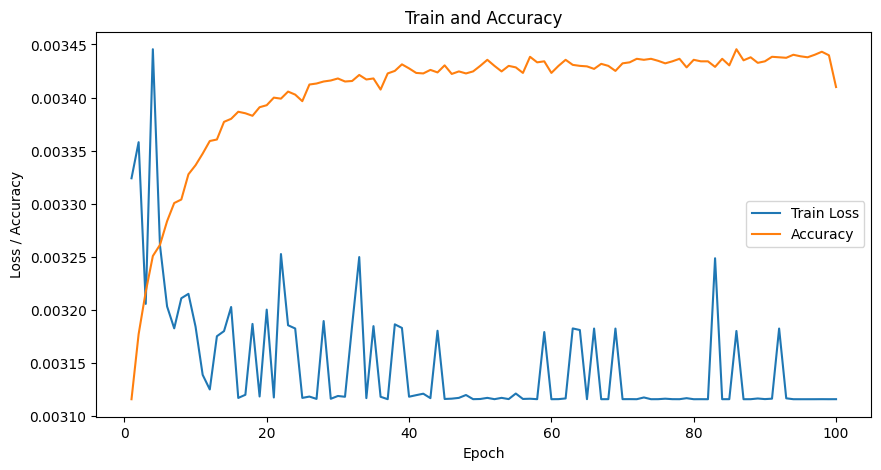

In [9]:
# Train model and save check point at different stages, then compute influence scores at each stage
model = DigitNet()
_, checkpoints, _, _, = train_func_classification(model, nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=0.0001), mnist_train_loader, mnist_test_loader, 100)

In [14]:
checkpoints = ['../checkpoint/DigitNet/DigitNet_epoch_10_0.1.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_20_0.2.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_40_0.4.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_60_0.6.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_80_0.8.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_100_1.0.pth']
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
mnist_influences = influence_at_checkpoints(mnist_train_loader, mnist_test_loader, model, optimizer,
                                           nn.CrossEntropyLoss(), checkpoints, "cpu", appro="lissa")

Calculating influence scores:   0%|          | 0/6 [00:00<?, ?it/s]

Checkpoint loaded at epoch 10 with completion rate 0.1
completion_rate: 0.1
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores:  17%|█▋        | 1/6 [03:17<16:28, 197.79s/it]

Checkpoint loaded at epoch 20 with completion rate 0.2
completion_rate: 0.2
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores:  33%|███▎      | 2/6 [06:42<13:27, 201.81s/it]

...

Calculating influence scores:  67%|██████▋   | 4/6 [13:34<06:49, 204.70s/it]

Checkpoint loaded at epoch 80 with completion rate 0.8
completion_rate: 0.8
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores:  83%|████████▎ | 5/6 [17:18<03:31, 211.58s/it]

Checkpoint loaded at epoch 100 with completion rate 1.0
completion_rate: 1.0
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores: 100%|██████████| 6/6 [20:48<00:00, 208.11s/it]


In [15]:
torch.tensor(mnist_influences).shape

C:\Users\yyxxc\AppData\Local\Temp\ipykernel_6096\3330782434.py:1: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ..\torch\csrc\utils\tensor_new.cpp:277.)
  torch.tensor(mnist_influences).shape


torch.Size([6, 60000])

In [16]:
def top_n_influences(ckpt_influences, train_dataset, num_per_row=10):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    ckpt_imgs = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=True)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        imgs = []
        for i, (img, label) in enumerate(top_influential_train_data):
            imgs.append(np.array(img))
            # ax[ckpt, i].imshow(np.array(img))
            # ax[ckpt, i].axis('off')
            # ax[ckpt, i].set_title(f"label: {label}\ninfluence: {influences[top_indexes[i]] * 100:.3f}\ncheckpoint at: {ckpt / 5}", fontsize=12)
        ckpt_imgs.append(imgs)
    # plt.tight_layout()
    # plt.show()
    return ckpt_imgs
    

original_mnist_train = datasets.MNIST('../data', train=True, download=False)
mnist_ckpt_imgs = top_n_influences(mnist_influences, original_mnist_train, num_per_row=20)

In [20]:
len(train_dataset)

2000

checkpoint: 0, mean: 36.37100765306123, variance: 6687.668463015247, skewness: 2.0083025524645923
checkpoint: 1, mean: 41.8122193877551, variance: 7615.327008849827, skewness: 1.785783484327671
checkpoint: 2, mean: 33.67348214285714, variance: 6211.378755986924, skewness: 2.1315760590794475
checkpoint: 3, mean: 40.350727040816324, variance: 7310.703074726514, skewness: 1.8414775395426846
checkpoint: 4, mean: 30.889770408163265, variance: 5683.579660661573, skewness: 2.2730347421690826
checkpoint: 5, mean: 41.72010204081633, variance: 7597.822677540609, skewness: 1.7887400343372268


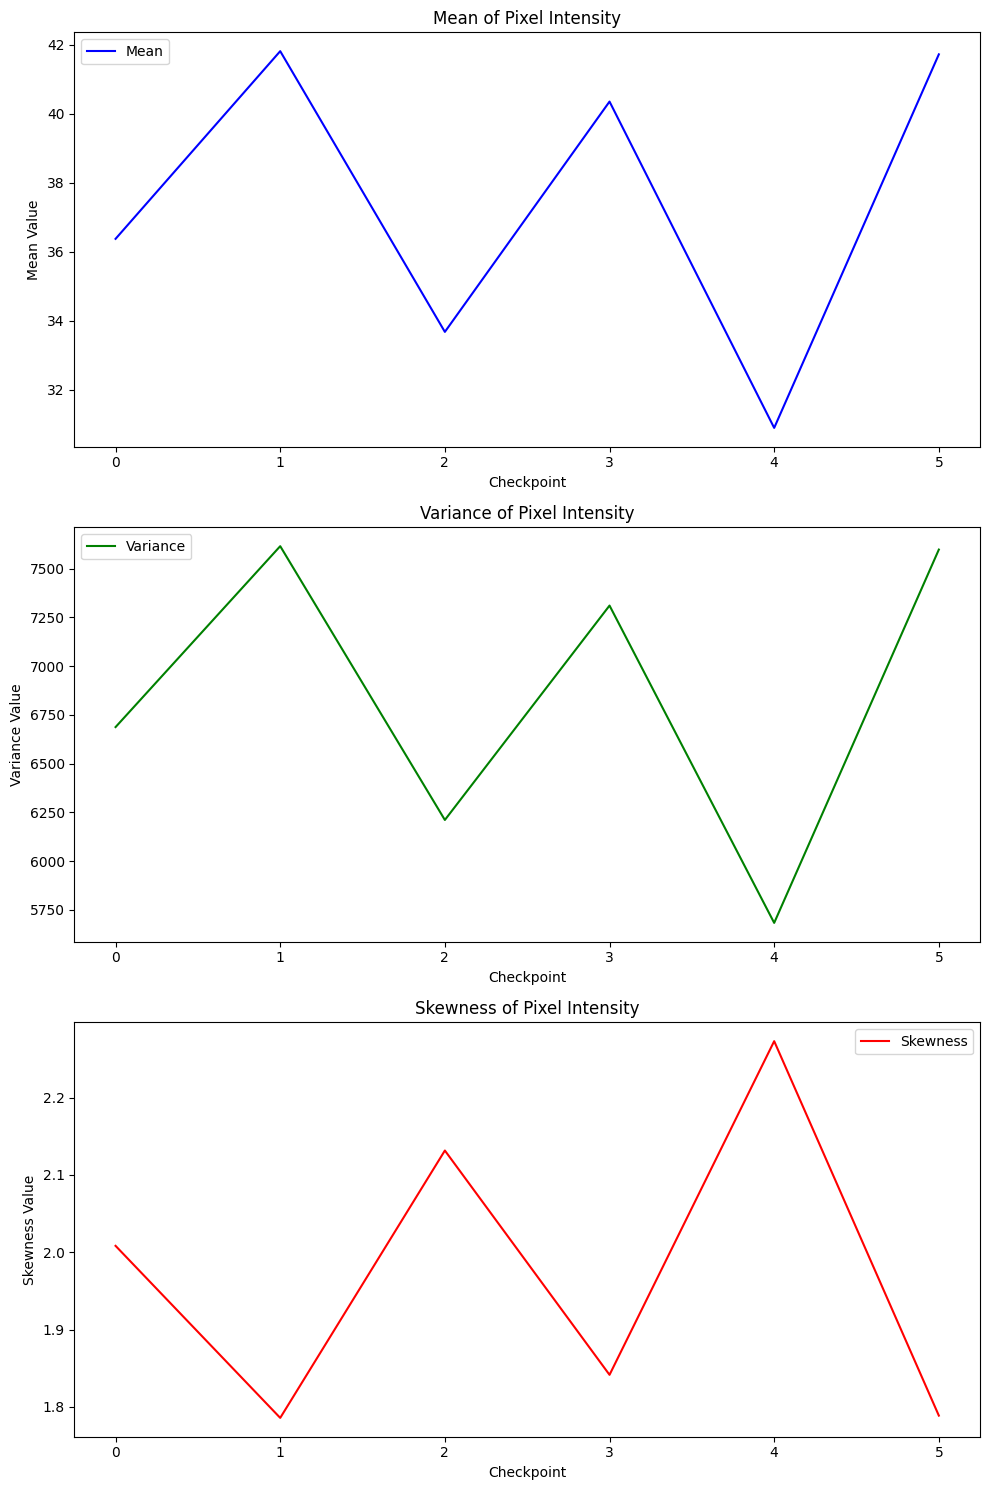

In [80]:
from scipy.stats import skew
def pixel_statistics(images):
    mean = np.mean(images)
    variance = np.var(images)
    skewness = skew(images.flatten())
    return mean, variance, skewness

means = []
skewnesses = []
variances = []
for ckpt, ckpt_imgs in enumerate(mnist_ckpt_imgs):
    mean, variance, skewness = pixel_statistics(ckpt_imgs)
    print(f"checkpoint: {ckpt}, mean: {mean}, variance: {variance}, skewness: {skewness}")
    means.append(mean)
    variances.append(variance)
    skewnesses.append(skewness)
fig, axes = plt.subplots(3, 1, figsize=(10, 15))
axes[0].plot(means, label="Mean", color='blue')
axes[0].set_title("Mean of Pixel Intensity")
axes[0].set_xlabel("Checkpoint")
axes[0].set_ylabel("Mean Value")
axes[0].legend()
axes[1].plot(variances, label="Variance", color='green')
axes[1].set_title("Variance of Pixel Intensity")
axes[1].set_xlabel("Checkpoint")
axes[1].set_ylabel("Variance Value")
axes[1].legend()
axes[2].plot(skewnesses, label="Skewness", color='red')
axes[2].set_title("Skewness of Pixel Intensity")
axes[2].set_xlabel("Checkpoint")
axes[2].set_ylabel("Skewness Value")
axes[2].legend()
plt.tight_layout()
plt.show()

checkpoint: 0, shape:(20, 784)
checkpoint: 1, shape:(20, 784)
checkpoint: 2, shape:(20, 784)
checkpoint: 3, shape:(20, 784)
checkpoint: 4, shape:(20, 784)
checkpoint: 5, shape:(20, 784)


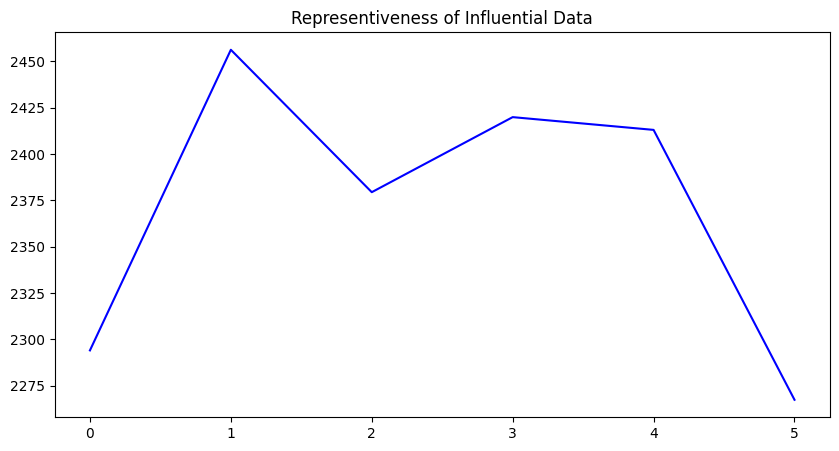

In [18]:
from sklearn.metrics.pairwise import euclidean_distances

def calc_representiveness(imgs):
    distances = euclidean_distances(imgs, imgs)
    mean_distance = np.mean(distances)
    return mean_distance

representivenesses = []
for ckpt, ckpt_imgs in enumerate(mnist_ckpt_imgs):
    ckpt_imgs = ckpt_imgs.reshape(-1, 28 * 28)
    print(f"checkpoint: {ckpt}, shape:{ckpt_imgs.shape}")
    mean_dist = calc_representiveness(ckpt_imgs)
    representivenesses.append(mean_dist)
plt.subplots(figsize=(10, 5))
plt.title("Representiveness of Influential Data")
plt.plot(representivenesses, label="Representiveness", color='blue')

learning speed stably decreases with increase checkpoint index
- when accuracy is rising, distances between most influential points is high;
- when accuracy is still, distance between most influential points are relatively lower;

Text(0.5, 1.0, 'Average In-Image Entropy')

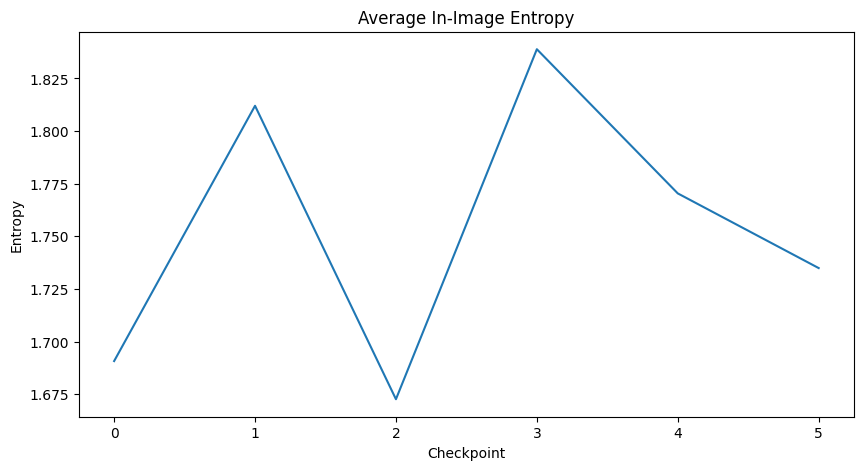

In [33]:
def calculate_entropy(image):
    hist, _ = np.histogram(image.flatten(), bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))

entropies = []
for imgs in mnist_ckpt_imgs:
    ckpt_entropies = [calculate_entropy(img) for img in imgs]
    mean_entropy = np.mean(ckpt_entropies)
    entropies.append(mean_entropy)
plt.subplots(figsize=(10, 5))
plt.plot(entropies)
plt.xlabel("Checkpoint")
plt.ylabel("Entropy")
plt.title("Average In-Image Entropy")

entropy at rapid learning stage is high; gradually reduce at later stage
**with a little rise at the last learning stage that accuracy rises slightly**

Text(0.5, 1.0, 'Inter-Image Entropy')

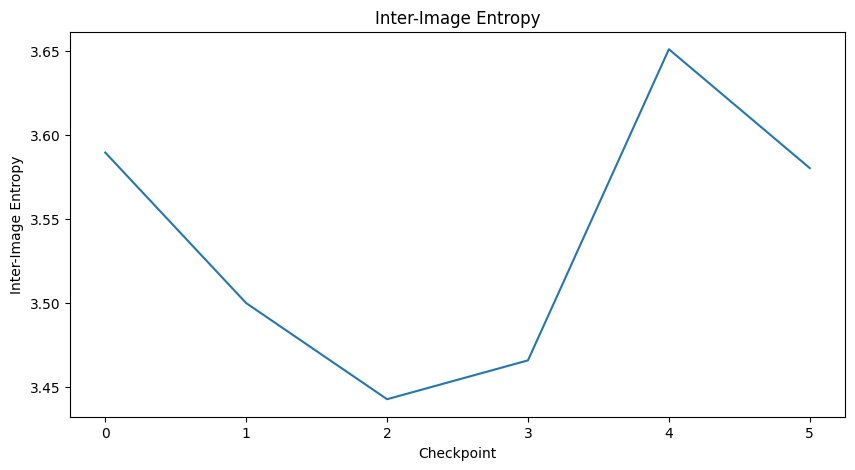

In [ ]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def image_pairwise_entropy(features):
    pairwise_distances = pdist(features, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=50, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    return entropy(distance_probs)

pw_entropies = []
for imgs in mnist_ckpt_imgs:
    imgs = np.array([img.flatten() for img in imgs])
    ckpt_entropies = image_pairwise_entropy(imgs)
    pw_entropies.append(ckpt_entropies)
plt.subplots(figsize=(10, 5))
plt.plot(pw_entropies)
plt.xlabel("Checkpoint")
plt.ylabel("Inter-Image Entropy")
plt.title("Inter-Image Entropy")

Z_imgs: (20, 10), volume: 8.70788138490684e+32
Z_imgs: (20, 10), volume: 3.520652246236301e+33
Z_imgs: (20, 10), volume: 1.5303766355358048e+33
Z_imgs: (20, 10), volume: 2.1642971117914944e+33
Z_imgs: (20, 10), volume: 1.9342535880135898e+33
Z_imgs: (20, 10), volume: 1.3541327208875055e+33


Text(0, 0.5, 'Volume')

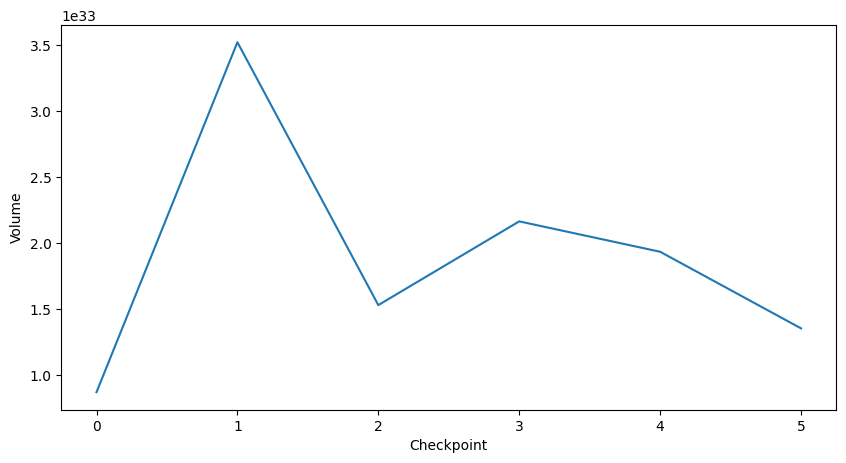

In [32]:
from sklearn.decomposition import PCA

def volume(images):
    return np.sqrt(np.linalg.det(images.T@images))

def pca(x, components):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=components)
    pca.fit(x_std)
    return pca.components_

volumes = []
for ckpt_imgs in mnist_ckpt_imgs:
    ckpt_imgs = ckpt_imgs.reshape(-1, 28 * 28)
    W = pca(ckpt_imgs, 10)
    Z_imgs = ckpt_imgs @ W.T
    print(f"Z_imgs: {Z_imgs.shape}, volume: {volume(Z_imgs)}")
    # print(f"checkpoint: {ckpt_imgs.shape}")
    volumes.append(volume(Z_imgs))
plt.subplots(figsize=(10, 5))
plt.plot(volumes)
plt.xlabel("Checkpoint")
plt.ylabel("Volume")

Checkpoint 2: **0.4**

In [84]:
len(train_dataset)

2000

In [24]:
model = NNSineModel()
def train_func_sine(model, criterion, optimizer, train_loader, validation_loader, epochs):
    train_losses = []
    val_losses = []

    for _ in range(epochs):
        model.train()
        loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            print(x_batch.shape)
            y_pred = model(x_batch.float())
            loss = criterion(y_pred, y_batch.float())
            loss.backward()
            optimizer.step()
            loss += loss.item()
        loss = loss / len(train_loader)
        train_losses.append(loss)
            
        model.eval()
        val_loss = 0.0
        for x_val_batch, y_val_batch in validation_loader:
            y_pred = model(x_val_batch)
            val_loss = criterion(y_pred, y_val_batch)
            val_loss += val_loss.item()
        val_loss /= len(validation_loader)
        val_losses.append(val_loss)
    epochs_range = range(1, epochs + 1)
    plt.figure(figsize=(10, 5))
    train_losses = [loss.detach().numpy() for loss in train_losses]
    val_losses = [loss.detach().numpy() for loss in val_losses]
    plt.plot(epochs_range, train_losses, label='Train Loss')
    plt.plot(epochs_range, val_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train and Validation Loss')
    plt.legend()
    plt.show()
    return model, train_losses, val_losses

ckpt_influences = calculate_influence_score_nn(train_loader, validation_loader, model, train_func_sine, nn.MSELoss(), 20, "cpu", per_point=-1, appro="cg")

TypeError: 'str' object is not callable

In [ ]:
np.save

In [69]:
sorted_influences = np.argsort(ckpt_influences)[::-1]
top_indexes = sorted_influences[:10]
x_vals = train_dataset.x_vals.numpy()[top_indexes]
x_vals = [str(round(x/math.pi, 4)) + "pi" for x in x_vals]
x_vals

['2.0pi',
 '1.998pi',
 '1.996pi',
 '1.994pi',
 '1.992pi',
 '1.99pi',
 '1.988pi',
 '1.986pi',
 '1.984pi',
 '1.982pi']